In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cargar los datos del proyecto
X = np.load("X.npy")
y = np.load("y.npy")
autores = np.load("autores.npy")

print("Total de imágenes:", len(X))
print("Dimensiones de las imágenes:", X.shape)

print("\nCantidad por clase:")
print(pd.Series(y).value_counts())

print("\nCantidad por autor y clase:")
display(pd.crosstab(
    pd.Series(autores, name="Autor"),
    pd.Series(y, name="Clase")
))

Total de imágenes: 1053
Dimensiones de las imágenes: (1053, 64, 64)

Cantidad por clase:
cerrados    554
abiertos    499
Name: count, dtype: int64

Cantidad por autor y clase:


Clase,abiertos,cerrados
Autor,,
benja,125,111
ivett,125,205
martin,125,122
melissa,124,116


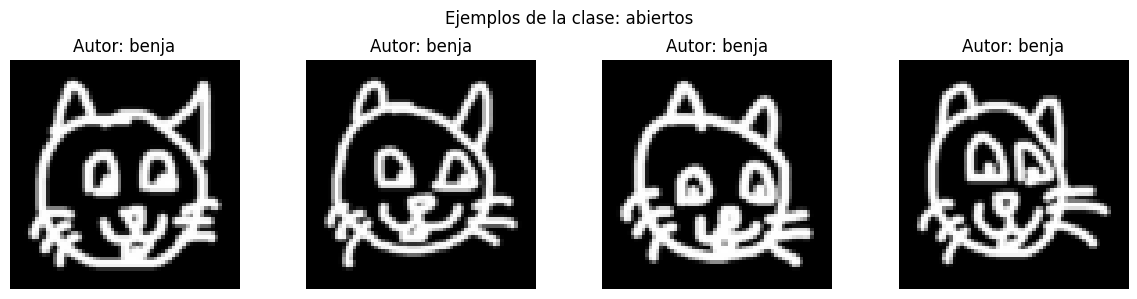

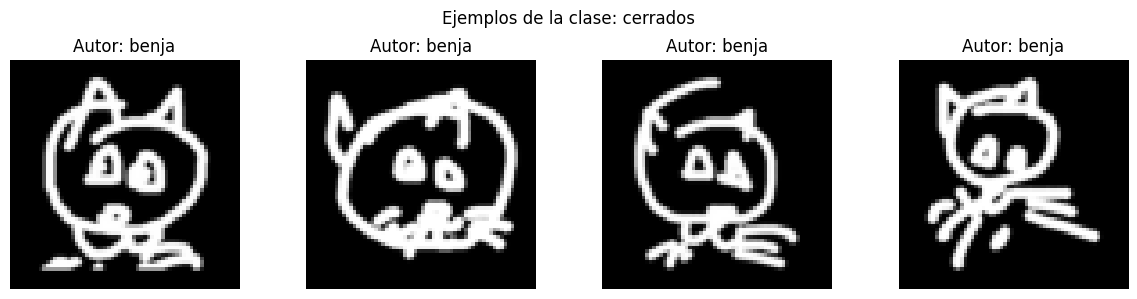

In [2]:
for clase in np.unique(y):
    indices = np.where(y == clase)[0][:4]

    fig, axes = plt.subplots(1, 4, figsize=(12, 3))
    fig.suptitle(f"Ejemplos de la clase: {clase}")

    for ax, idx in zip(axes, indices):
        ax.imshow(X[idx], cmap="gray")
        ax.set_title(f"Autor: {autores[idx]}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [3]:
import sys

sys.argv = ["x"]
import train_minimal_cnn as t

t.run(t.parse_args())

seed=17 epoch=01 loss=0.6941 acc=0.536 val_loss=0.6911
seed=17 epoch=02 loss=0.6917 acc=0.536 val_loss=0.6907
seed=17 epoch=03 loss=0.6903 acc=0.536 val_loss=0.6900
seed=17 epoch=04 loss=0.6894 acc=0.536 val_loss=0.6887
seed=17 epoch=05 loss=0.6892 acc=0.536 val_loss=0.6878
seed=17 epoch=06 loss=0.6866 acc=0.536 val_loss=0.6862
seed=17 epoch=07 loss=0.6829 acc=0.540 val_loss=0.6829
seed=17 epoch=08 loss=0.6802 acc=0.541 val_loss=0.6800
seed=17 epoch=09 loss=0.6845 acc=0.558 val_loss=0.6771
seed=17 epoch=10 loss=0.6728 acc=0.595 val_loss=0.6704
seed=17 epoch=11 loss=0.6608 acc=0.602 val_loss=0.6569
seed=17 epoch=12 loss=0.6617 acc=0.625 val_loss=0.6472
seed=17 epoch=13 loss=0.6422 acc=0.698 val_loss=0.6395
seed=17 epoch=14 loss=0.6390 acc=0.699 val_loss=0.6296
seed=17 epoch=15 loss=0.6374 acc=0.650 val_loss=0.6260
seed=17 epoch=16 loss=0.6239 acc=0.679 val_loss=0.6335
seed=17 epoch=17 loss=0.6127 acc=0.729 val_loss=0.6074
seed=17 epoch=18 loss=0.6181 acc=0.688 val_loss=0.6009
seed=17 ep

In [5]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score
from sklearn.preprocessing import LabelEncoder

# Usar la misma separación por autor de la CNN
X = np.load("X.npy")
y = np.load("y.npy")
autores = np.load("autores.npy")

# Codificar las etiquetas de texto como 0 y 1
encoder = LabelEncoder()
y_num = encoder.fit_transform(y)

# Revisar cómo se define la función de separación
import inspect
print(inspect.signature(t.split_by_author))
print(inspect.getsource(t.split_by_author))

(labels: 'np.ndarray', authors: 'np.ndarray', test_author: 'str', validation_fraction: 'float', seed: 'int') -> 'tuple[np.ndarray, np.ndarray, np.ndarray]'
def split_by_author(
    labels: np.ndarray,
    authors: np.ndarray,
    test_author: str,
    validation_fraction: float,
    seed: int,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Separa al autor de prueba antes de crear train/validation."""
    test_indices = np.flatnonzero(authors == test_author)
    train_pool = np.flatnonzero(authors != test_author)
    if len(test_indices) == 0:
        raise ValueError(f"No hay dibujos del autor de prueba '{test_author}'.")
    if set(np.unique(labels[test_indices])) != set(CLASS_NAMES):
        raise ValueError(
            f"El autor de prueba '{test_author}' debe tener ejemplos de ambas clases."
        )
    if len(train_pool) == 0:
        raise ValueError("No quedan autores para entrenar después de reservar el test.")

    rng = np.random.default_rng(seed)
    train_indices

In [6]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

# Preparar datos
X = np.load("X.npy").astype(np.float32) / 255.0
y_text = np.load("y.npy")
autores = np.load("autores.npy")

encoder = LabelEncoder()
y = encoder.fit_transform(y_text)

# Convertir imágenes 64x64 a vectores de 4096 valores
X_flat = X.reshape(len(X), 4096)

# Modelo MLP: 4096 -> 128 -> 2
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4096, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.net(x)

# Entrenar con cinco semillas y el split por autor
resultados_mlp = []

for seed in [17, 37, 73, 101, 202]:
    torch.manual_seed(seed)
    np.random.seed(seed)

    train_idx, val_idx, test_idx = t.split_by_author(
        labels=y_text,
        authors=autores,
        test_author="martin",
        validation_fraction=0.2,
        seed=seed
    )

    model = MLP()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    Xt = torch.tensor(X_flat[train_idx], dtype=torch.float32)
    yt = torch.tensor(y[train_idx], dtype=torch.long)
    Xv = torch.tensor(X_flat[val_idx], dtype=torch.float32)
    yv = torch.tensor(y[val_idx], dtype=torch.long)
    Xtest = torch.tensor(X_flat[test_idx], dtype=torch.float32)
    ytest = y[test_idx]

    for epoch in range(30):
        model.train()
        optimizer.zero_grad()
        loss = criterion(model(Xt), yt)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        pred = model(Xtest).argmax(dim=1).numpy()

    acc = accuracy_score(ytest, pred)
    f1 = f1_score(ytest, pred, average="macro")
    bal_acc = balanced_accuracy_score(ytest, pred)

    resultados_mlp.append({
        "semilla": seed,
        "accuracy": acc,
        "f1_macro": f1,
        "balanced_accuracy": bal_acc
    })

    print(
        f"MLP seed={seed}: accuracy={acc:.3f}, "
        f"F1={f1:.3f}, balanced_accuracy={bal_acc:.3f}"
    )

df_mlp = pd.DataFrame(resultados_mlp)
display(df_mlp)

MLP seed=17: accuracy=0.846, F1=0.846, balanced_accuracy=0.847
MLP seed=37: accuracy=0.814, F1=0.811, balanced_accuracy=0.815
MLP seed=73: accuracy=0.818, F1=0.817, balanced_accuracy=0.819
MLP seed=101: accuracy=0.862, F1=0.862, balanced_accuracy=0.863
MLP seed=202: accuracy=0.789, F1=0.788, balanced_accuracy=0.791


,semilla,accuracy,f1_macro,balanced_accuracy
0,17,0.846154,0.845584,0.847016
1,37,0.813765,0.810785,0.815410
2,73,0.817814,0.816611,0.818918
3,101,0.862348,0.861839,0.863213
4,202,0.789474,0.787941,0.790623


In [7]:
import json
from pathlib import Path

ruta = Path("model_results/evaluation.json")

print("¿Existe evaluation.json?", ruta.exists())

if ruta.exists():
    with open(ruta, "r", encoding="utf-8") as f:
        resultados_cnn = json.load(f)

    print(json.dumps(resultados_cnn, indent=2, ensure_ascii=False)[:12000])

¿Existe evaluation.json? True
{
  "test_author": "martin",
  "train_authors": [
    "benja",
    "ivett",
    "melissa"
  ],
  "classes": [
    "abiertos",
    "cerrados"
  ],
  "test_examples": 247,
  "split_seed": 42,
  "seeds": [
    17,
    37,
    73,
    101,
    202
  ],
  "runs": [
    {
      "seed": 17,
      "accuracy": 0.48582995951417,
      "confusion_matrix": [
        [
          4,
          121
        ],
        [
          6,
          116
        ]
      ],
      "per_class": {
        "abiertos": {
          "precision": 0.4,
          "recall": 0.032,
          "f1": 0.059259259259259255
        },
        "cerrados": {
          "precision": 0.48945147679324896,
          "recall": 0.9508196721311475,
          "f1": 0.6462395543175488
        }
      },
      "best_epoch": 29
    },
    {
      "seed": 37,
      "accuracy": 0.5101214574898786,
      "confusion_matrix": [
        [
          18,
          107
        ],
        [
          14,
          108
    

In [8]:
import numpy as np
import pandas as pd
from scipy.stats import t

# Resultados de CNN guardados en evaluation.json
cnn_runs = resultados_cnn["runs"]

cnn_acc = np.array([r["accuracy"] for r in cnn_runs])

# F1 macro de CNN: promedio del F1 de las dos clases
cnn_f1 = np.array([
    np.mean([r["per_class"][c]["f1"] for c in resultados_cnn["classes"]])
    for r in cnn_runs
])

# Resultados del MLP
mlp_acc = df_mlp["accuracy"].to_numpy()
mlp_f1 = df_mlp["f1_macro"].to_numpy()

def resumen(valores):
    n = len(valores)
    media = np.mean(valores)
    desv = np.std(valores, ddof=1)
    margen = t.ppf(0.975, n - 1) * desv / np.sqrt(n)
    return {
        "Media ± desv.": f"{media:.3f} ± {desv:.3f}",
        "IC 95 %": f"[{media-margen:.3f}, {media+margen:.3f}]"
    }

filas = []
for modelo, acc, f1 in [
    ("CNN", cnn_acc, cnn_f1),
    ("MLP", mlp_acc, mlp_f1)
]:
    for metrica, valores in [
        ("Accuracy", acc),
        ("F1 macro", f1)
    ]:
        filas.append({
            "Modelo": modelo,
            "Métrica": metrica,
            **resumen(valores)
        })

display(pd.DataFrame(filas))

,Modelo,Métrica,Media ± desv.,IC 95 %
0,CNN,Accuracy,0.505 ± 0.017,"[0.484, 0.526]"
1,CNN,F1 macro,0.421 ± 0.049,"[0.360, 0.482]"
2,MLP,Accuracy,0.826 ± 0.029,"[0.790, 0.861]"
3,MLP,F1 macro,0.825 ± 0.029,"[0.788, 0.861]"


In [11]:
import importlib
import train_minimal_cnn as cnn_module

t = importlib.reload(cnn_module)

print("Módulo:", t.__file__)
print("Tiene run:", hasattr(t, "run"))
print("Tiene split_by_author:", hasattr(t, "split_by_author"))

Módulo: C:\Users\Benja\cc431-pc2-gatitos\train_minimal_cnn.py
Tiene run: True
Tiene split_by_author: True


In [12]:
import inspect

print(inspect.getsource(t.run))

def run(args: argparse.Namespace) -> None:
    images, labels, authors = load_prepared_arrays(args.data_dir)
    if not 0 < args.validation_fraction < 0.5:
        raise ValueError("--validation-fraction debe estar entre 0 y 0.5.")
    if args.cam_per_class < 0:
        raise ValueError("--cam-per-class no puede ser negativo.")

    output_dir = args.output_dir
    output_dir.mkdir(parents=True, exist_ok=True)
    runs: list[dict[str, object]] = []
    train_authors = sorted(set(authors) - {args.test_author})
    if not train_authors:
        raise ValueError("No hay autores disponibles para entrenamiento.")

    for seed in args.seeds:
        train_indices, validation_indices, test_indices = split_by_author(
            labels,
            authors,
            args.test_author,
            args.validation_fraction,
            args.split_seed,
        )
        model, history, best_epoch = train_one_seed(
            images,
            labels,
            train_indices,
            

Autor reservado para prueba: martin
Cantidad de dibujos de prueba: 247

Semilla: 17
Accuracy: 0.486


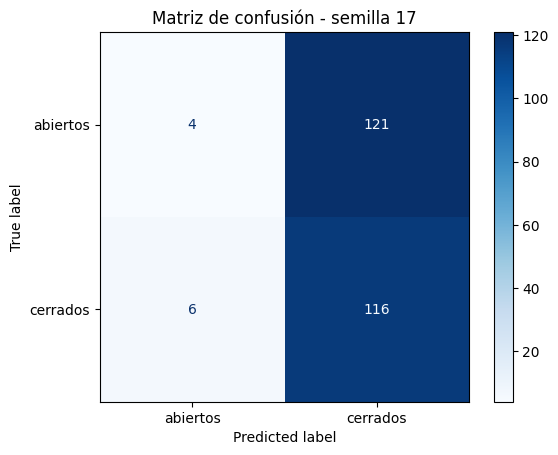

,precision,recall,f1
abiertos,0.400000,0.03200,0.059259
cerrados,0.489451,0.95082,0.646240



Semilla: 37
Accuracy: 0.510


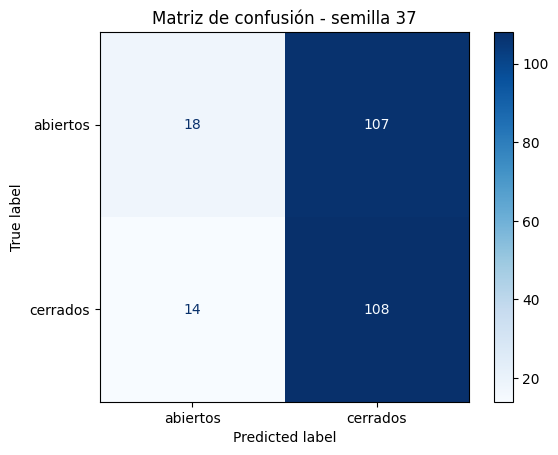

,precision,recall,f1
abiertos,0.562500,0.144000,0.229299
cerrados,0.502326,0.885246,0.640950



Semilla: 73
Accuracy: 0.530


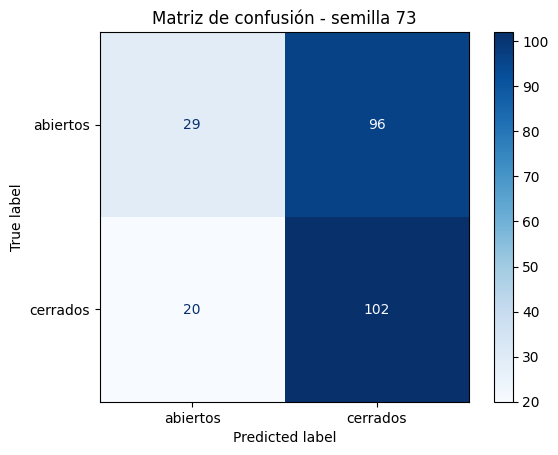

,precision,recall,f1
abiertos,0.591837,0.232000,0.333333
cerrados,0.515152,0.836066,0.637500



Semilla: 101
Accuracy: 0.494


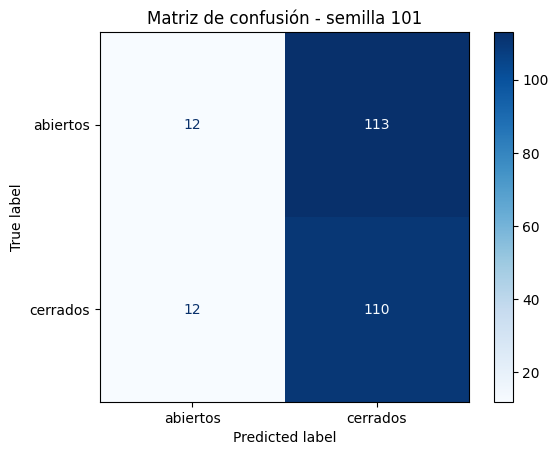

,precision,recall,f1
abiertos,0.500000,0.096000,0.161074
cerrados,0.493274,0.901639,0.637681



Semilla: 202
Accuracy: 0.506


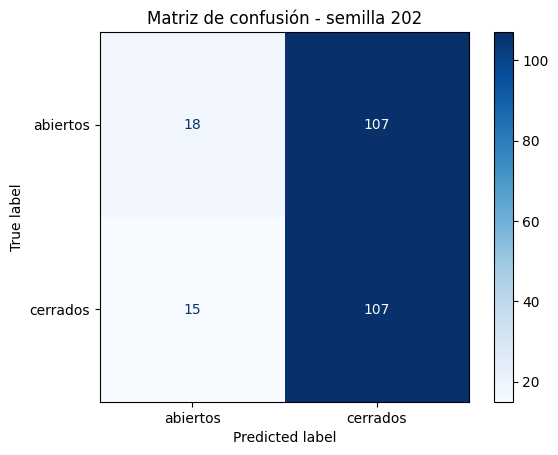

,precision,recall,f1
abiertos,0.545455,0.144000,0.227848
cerrados,0.500000,0.877049,0.636905


In [13]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

# Leer resultados guardados de la CNN
with open("model_results/evaluation.json", encoding="utf-8") as f:
    evaluation = json.load(f)

print("Autor reservado para prueba:", evaluation["test_author"])
print("Cantidad de dibujos de prueba:", evaluation["test_examples"])

# Mostrar métricas de cada semilla
for run in evaluation["runs"]:
    print(f"\nSemilla: {run['seed']}")
    print(f"Accuracy: {run['accuracy']:.3f}")

    matriz = np.array(run["confusion_matrix"])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=evaluation["classes"]
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Matriz de confusión - semilla {run['seed']}")
    plt.show()

    metricas = pd.DataFrame(run["per_class"]).T
    display(metricas)

Imágenes CAM: model_results\seed_101\cam
seed_101_abiertos_sample_250_pred_cerrados.png


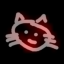

seed_101_abiertos_sample_251_pred_cerrados.png


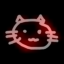

seed_101_cerrados_sample_815_pred_cerrados.png


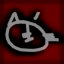

seed_101_cerrados_sample_816_pred_cerrados.png


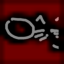

Imágenes CAM: model_results\seed_17\cam
seed_17_abiertos_sample_250_pred_cerrados.png


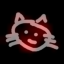

seed_17_abiertos_sample_251_pred_cerrados.png


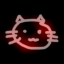

seed_17_cerrados_sample_815_pred_cerrados.png


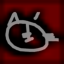

seed_17_cerrados_sample_816_pred_cerrados.png


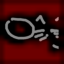

Imágenes CAM: model_results\seed_202\cam
seed_202_abiertos_sample_250_pred_cerrados.png


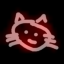

seed_202_abiertos_sample_251_pred_cerrados.png


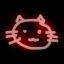

seed_202_cerrados_sample_815_pred_cerrados.png


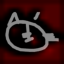

seed_202_cerrados_sample_816_pred_cerrados.png


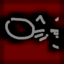

Imágenes CAM: model_results\seed_37\cam
seed_37_abiertos_sample_250_pred_cerrados.png


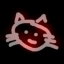

seed_37_abiertos_sample_251_pred_cerrados.png


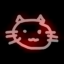

seed_37_cerrados_sample_815_pred_cerrados.png


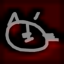

seed_37_cerrados_sample_816_pred_cerrados.png


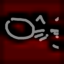

Imágenes CAM: model_results\seed_73\cam
seed_73_abiertos_sample_250_pred_cerrados.png


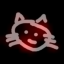

seed_73_abiertos_sample_251_pred_cerrados.png


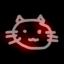

seed_73_cerrados_sample_815_pred_cerrados.png


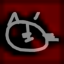

seed_73_cerrados_sample_816_pred_cerrados.png


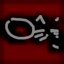

In [14]:
from IPython.display import display, Image
from pathlib import Path

carpetas_cam = sorted(Path("model_results").glob("seed_*/cam"))

for carpeta in carpetas_cam:
    imagenes = sorted([
        *carpeta.glob("*.png"),
        *carpeta.glob("*.jpg"),
        *carpeta.glob("*.jpeg")
    ])

    if imagenes:
        print(f"Imágenes CAM: {carpeta}")
        for archivo in imagenes:
            print(archivo.name)
            display(Image(filename=str(archivo)))

In [15]:
from IPython.display import Markdown, display

display(Markdown("""
### Conclusiones

- Se trabajó con 1053 dibujos: 499 de ojos abiertos y 554 de ojos cerrados.
- La evaluación reservó los dibujos de Martin para probar la generalización a un autor no usado en el entrenamiento.
- La CNN obtuvo un accuracy medio cercano al 50.5 % y mostró dificultades para reconocer la clase abiertos.
- El MLP obtuvo resultados superiores en la ejecución realizada; la comparación debe interpretarse considerando que ambos modelos deben usar el mismo preprocesamiento y la misma separación de datos.
"""))


### Conclusiones

- Se trabajó con 1053 dibujos: 499 de ojos abiertos y 554 de ojos cerrados.
- La evaluación reservó los dibujos de Martin para probar la generalización a un autor no usado en el entrenamiento.
- La CNN obtuvo un accuracy medio cercano al 50.5 % y mostró dificultades para reconocer la clase abiertos.
- El MLP obtuvo resultados superiores en la ejecución realizada; la comparación debe interpretarse considerando que ambos modelos deben usar el mismo preprocesamiento y la misma separación de datos.
